In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [2]:
data = {
    "annual_income_k": [15, 18, 20, 22, 25, 28, 32, 35, 38, 40, 60, 65, 70, 75, 80, 85, 90, 95, 120, 125, 130, 135, 140, 145],
    "spending_score": [20, 25, 18, 30, 22, 35, 28, 40, 32, 45, 60, 65, 55, 70, 62, 75, 68, 80, 85, 90, 80, 95, 88, 92]
}

df = pd.DataFrame(data)

print(df)

    annual_income_k  spending_score
0                15              20
1                18              25
2                20              18
3                22              30
4                25              22
5                28              35
6                32              28
7                35              40
8                38              32
9                40              45
10               60              60
11               65              65
12               70              55
13               75              70
14               80              62
15               85              75
16               90              68
17               95              80
18              120              85
19              125              90
20              130              80
21              135              95
22              140              88
23              145              92


In [4]:
df.to_csv("customer_segments.csv", index=False)

In [5]:
print(df.head())

   annual_income_k  spending_score
0               15              20
1               18              25
2               20              18
3               22              30
4               25              22


In [6]:
print(df.shape)

(24, 2)


In [7]:

df = pd.read_csv("customer_segments.csv")

print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

First Five Records:
   annual_income_k  spending_score
0               15              20
1               18              25
2               20              18
3               22              30
4               25              22

Dataset Shape:
(24, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   annual_income_k  24 non-null     int64
 1   spending_score   24 non-null     int64
dtypes: int64(2)
memory usage: 516.0 bytes

Statistical Description:
       annual_income_k  spending_score
count        24.000000       24.000000
mean         70.333333       56.666667
std          43.880932       25.981041
min          15.000000       18.000000
25%          31.000000       31.500000
50%          67.500000       61.000000
75%         101.250000       80.000000
max         145.000000       95.000000

Missing Values:
annual_in

In [8]:
X = df[["annual_income_k", "spending_score"]]

print("Selected Features:")
print(X)

print("\nShape of X:")
print(X.shape)

Selected Features:
    annual_income_k  spending_score
0                15              20
1                18              25
2                20              18
3                22              30
4                25              22
5                28              35
6                32              28
7                35              40
8                38              32
9                40              45
10               60              60
11               65              65
12               70              55
13               75              70
14               80              62
15               85              75
16               90              68
17               95              80
18              120              85
19              125              90
20              130              80
21              135              95
22              140              88
23              145              92

Shape of X:
(24, 2)


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Features:")
print(X_scaled)

print("\nScaled Data Shape:")
print(X_scaled.shape)

Scaled Features:
[[-1.28810922 -1.44163921]
 [-1.21827197 -1.24505204]
 [-1.17171381 -1.52027407]
 [-1.12515564 -1.04846488]
 [-1.0553184  -1.36300434]
 [-0.98548115 -0.85187771]
 [-0.89236482 -1.12709974]
 [-0.82252757 -0.65529055]
 [-0.75269033 -0.96983001]
 [-0.70613216 -0.45870338]
 [-0.24055052  0.13105811]
 [-0.12415511  0.32764527]
 [-0.00775969 -0.06552905]
 [ 0.10863572  0.52423244]
 [ 0.22503113  0.20969298]
 [ 0.34142654  0.7208196 ]
 [ 0.45782195  0.44559757]
 [ 0.57421736  0.91740677]
 [ 1.15619442  1.11399393]
 [ 1.27258983  1.3105811 ]
 [ 1.38898524  0.91740677]
 [ 1.50538065  1.50716826]
 [ 1.62177607  1.23194623]
 [ 1.73817148  1.38921596]]

Scaled Data Shape:
(24, 2)


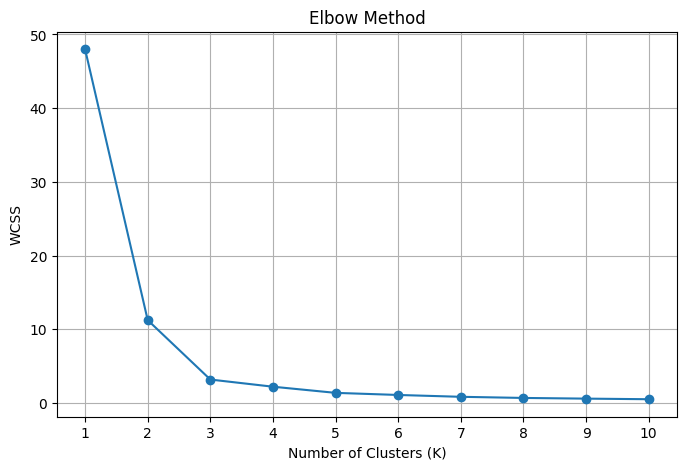

In [10]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_scaled)

labels = kmeans.labels_

df["Cluster"] = labels

print("Cluster Labels:")
print(labels)

print("\nDataset with Cluster Labels:")
print(df)

Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 1 1 1 1 1 1]

Dataset with Cluster Labels:
    annual_income_k  spending_score  Cluster
0                15              20        0
1                18              25        0
2                20              18        0
3                22              30        0
4                25              22        0
5                28              35        0
6                32              28        0
7                35              40        0
8                38              32        0
9                40              45        0
10               60              60        2
11               65              65        2
12               70              55        2
13               75              70        2
14               80              62        2
15               85              75        2
16               90              68        2
17               95              80        2
18              120              85        1
19  

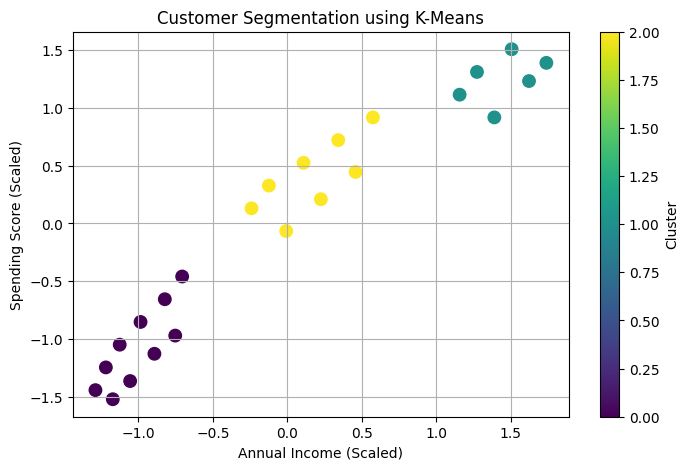

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=80
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()


In [13]:
cluster_analysis = df.groupby("Cluster")[["annual_income_k", "spending_score"]].mean()

print("Customer Cluster Analysis:")
print(cluster_analysis)

Customer Cluster Analysis:
         annual_income_k  spending_score
Cluster                                 
0                   27.3       29.500000
1                  132.5       88.333333
2                   77.5       66.875000


In [14]:
score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)

Silhouette Score: 0.675208222346614


In [15]:
new_customer = np.array([[75, 70]])

new_customer_scaled = scaler.transform(new_customer)

predicted_cluster = kmeans.predict(new_customer_scaled)

print("New Customer Details:")
print("Annual Income:", new_customer[0][0], "thousand")
print("Spending Score:", new_customer[0][1])

print("\nPredicted Cluster:", predicted_cluster[0])

New Customer Details:
Annual Income: 75 thousand
Spending Score: 70

Predicted Cluster: 2


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


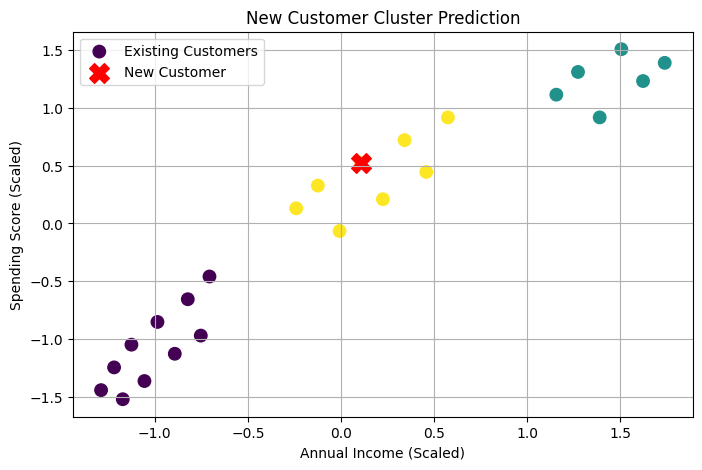

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=80,
    label="Existing Customers"
)

plt.scatter(
    new_customer_scaled[:, 0],
    new_customer_scaled[:, 1],
    color="red",
    marker="X",
    s=200,
    label="New Customer"
)

plt.title("New Customer Cluster Prediction")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
centers_scaled = kmeans.cluster_centers_

centers_original = scaler.inverse_transform(centers_scaled)

centroid_df = pd.DataFrame(
    centers_original,
    columns=["annual_income_k", "spending_score"]
)

print("Cluster Centroids in Original Units:")
print(centroid_df)

Cluster Centroids in Original Units:
   annual_income_k  spending_score
0             27.3       29.500000
1            132.5       88.333333
2             77.5       66.875000


In [18]:
score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", round(score, 3))

if score > 0.5:
    print("The clusters are reasonably well separated.")
elif score > 0:
    print("The clusters have some separation, but may overlap.")
else:
    print("The clustering may have poorly separated groups.")

Silhouette Score: 0.675
The clusters are reasonably well separated.
